# Modelagem e Avaliação — Comparação de Modelos (Etapa 2)

Tech Challenge Fase 1 (FIAP). Este notebook cobre o entregável da Etapa 2:
**tabela comparativa de modelos (Regressão Logística, Random Forest, MLP)
e justificativa da escolha do modelo campeão**.

O treino de produção já está em `src/churn/train.py` — ele roda validação
cruzada, treina os três candidatos, escolhe o campeão pelo F1 médio da
validação cruzada e salva os artefatos (`docs/model_comparison.csv`,
`models/champion.joblib`). Este notebook **não duplica esse treino**:
recarrega os mesmos candidatos e o mesmo split (mesma seed, via
`churn.config`) para visualizar o comparativo com mais profundidade,
validar os hiperparâmetros do Random Forest (seção 4), entender o que o
campeão aprendeu (seção 7) e documentar o raciocínio por trás da escolha.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score

from churn import config, data
from churn.models import BASELINE_NAME, get_candidates

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Tabela comparativa (Etapa 2 — entregável)

Resultado já produzido por `python -m churn.train`. As colunas `cv_f1_*`
vêm da validação cruzada (5 folds, só no treino); as demais vêm do
conjunto de teste (20%, estratificado, seed fixa).

O campeão é o modelo com maior **F1 médio na validação cruzada**, não no
teste. O teste fica reservado para a estimativa final de desempenho: se
ele também fosse usado para escolher o modelo, viraria mais um conjunto de
validação e as métricas reportadas ficariam otimistas.

In [2]:
results = pd.read_csv(config.DOCS_DIR / "model_comparison.csv")
results = results.sort_values("cv_f1_mean", ascending=False).reset_index(drop=True)
results

,model,cv_f1_mean,cv_f1_std,precision,recall,f1,roc_auc,pr_auc,precision_at_k
0,random_forest,0.650210,0.018056,0.535316,0.770053,0.631579,0.852554,0.662610,0.771429
1,logistic_regression,0.640062,0.021128,0.510490,0.780749,0.617336,0.848854,0.645293,0.764286
2,mlp,0.615479,0.033060,0.683398,0.473262,0.559242,0.844444,0.634753,0.742857


In [3]:
champion_name = results.loc[0, "model"]
print(f"Campeao (maior F1 medio na validacao cruzada): {champion_name}")

Campeao (maior F1 medio na validacao cruzada): random_forest


## 2. Comparação visual das métricas

F1 é o critério de seleção (Etapa 1), mas olhamos todas as métricas juntas
para entender *como* cada modelo chega ao seu F1.


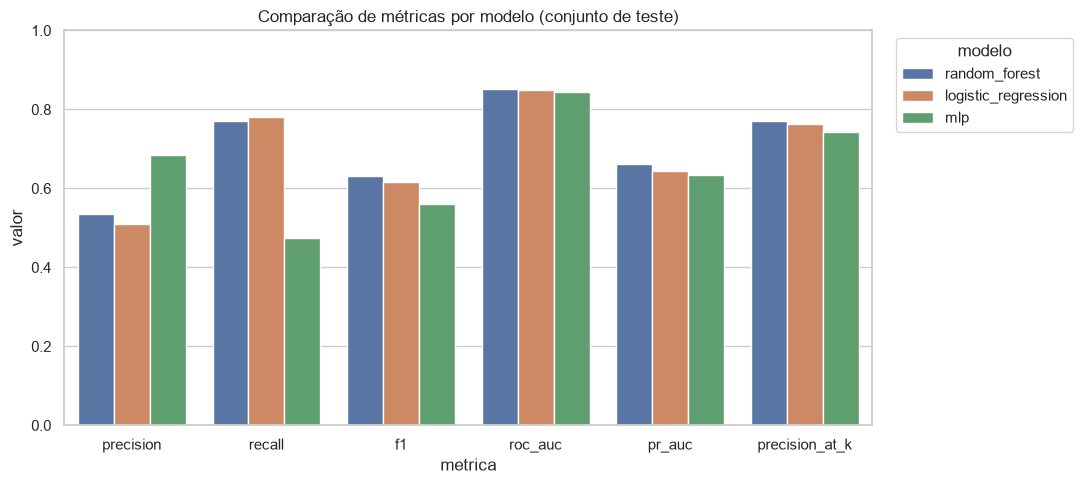

In [4]:
metrics_to_plot = ["precision", "recall", "f1", "roc_auc", "pr_auc", "precision_at_k"]

plot_df = results.melt(id_vars="model", value_vars=metrics_to_plot,
                        var_name="metrica", value_name="valor")

plt.figure(figsize=(11, 5))
sns.barplot(data=plot_df, x="metrica", y="valor", hue="model")
plt.ylim(0, 1)
plt.title("Comparação de métricas por modelo (conjunto de teste)")
plt.legend(title="modelo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


**Leitura:** o Random Forest e a Regressão Logística ficam próximos em
quase todas as métricas — a diferença que decide o F1 é a precisão
(Random Forest um pouco mais preciso, com recall praticamente igual). O
MLP se destaca isoladamente em precisão, mas paga um preço alto em recall:
ele é o mais conservador dos três, o que joga seu F1 para baixo apesar de
"acertar mais quando aponta risco".


## 3. Robustez via validação cruzada

`train.py` já reporta média e desvio-padrão do F1 em 5-fold CV
(`cv_f1_mean`, `cv_f1_std`). Aqui recalculamos os *scores por fold*
(mesma seed, mesmo `StratifiedKFold`) para visualizar a variância, não só
o resumo.


In [5]:
df_clean = data.load_clean()
X_train, X_test, y_train, y_test = data.split(df_clean)

cv = StratifiedKFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)

cv_scores = {}
for name, pipeline in get_candidates().items():
    cv_scores[name] = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)

cv_df = pd.DataFrame(cv_scores)
cv_df


,logistic_regression,random_forest,mlp
0,0.663144,0.662125,0.629758
1,0.616622,0.626950,0.558935
2,0.612565,0.629730,0.611722
3,0.652284,0.669388,0.660746
4,0.655693,0.662857,0.616236


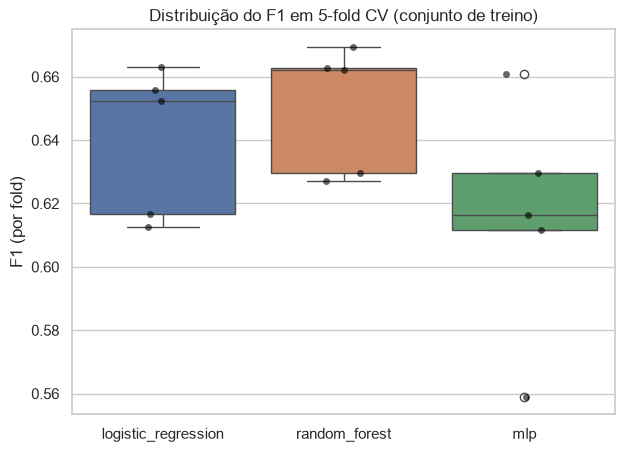

In [6]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=cv_df)
sns.stripplot(data=cv_df, color="black", size=5, alpha=0.6)
plt.ylabel("F1 (por fold)")
plt.title("Distribuição do F1 em 5-fold CV (conjunto de treino)")
plt.show()


**Leitura:** as distribuições de Random Forest e Regressão Logística se
sobrepõem bastante — a vantagem do Random Forest no F1 médio (0,650 vs
0,640) é pequena diante da variância entre folds, então ele vence mas por
margem estreita. O MLP tem a mediana mais baixa e maior dispersão: além de
pior, é o mais instável dos três.


## 4. Random Forest: busca de hiperparâmetros

Os hiperparâmetros do Random Forest em `churn.models` (`n_estimators=300`,
`min_samples_leaf=5`) foram escolhidos como valores razoáveis, sem
otimização. Aqui testamos se uma busca em grade (`GridSearchCV`) com a
mesma validação cruzada — 5 folds estratificados, só no treino, F1 como
critério — encontra uma configuração melhor. O conjunto de teste não
participa da busca.

A grade cobre os dois controles principais de complexidade das árvores —
profundidade máxima (`max_depth`) e tamanho mínimo da folha
(`min_samples_leaf`) — e a fração de features sorteada a cada divisão
(`max_features`). `n_estimators` fica fixo em 300: mais árvores reduzem a
variância da floresta, mas não mudam o que cada árvore aprende.

In [7]:
rf_grid = {
    "model__max_depth": [None, 8, 12],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__max_features": ["sqrt", 0.5],
}

rf_search = GridSearchCV(
    get_candidates()["random_forest"],
    rf_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
rf_search.fit(X_train, y_train)

grid_results = (
    pd.DataFrame(rf_search.cv_results_)
    .rename(columns=lambda c: c.replace("param_model__", ""))
    .rename(columns={
        "mean_test_score": "cv_f1_mean",
        "std_test_score": "cv_f1_std",
        "mean_train_score": "train_f1_mean",
        "rank_test_score": "rank",
    })
    [["rank", "max_depth", "min_samples_leaf", "max_features",
      "cv_f1_mean", "cv_f1_std", "train_f1_mean"]]
    .sort_values("rank")
    .reset_index(drop=True)
)

# Registro do experimento (Etapa 2: "registrar os resultados").
grid_results.astype({"max_depth": str}).to_csv(config.DOCS_DIR / "rf_grid_search.csv", index=False)
grid_results.head(10)

,rank,max_depth,min_samples_leaf,max_features,cv_f1_mean,cv_f1_std,train_f1_mean
0,1,None,5,sqrt,0.650210,0.018056,0.747554
1,2,12,5,sqrt,0.649235,0.014972,0.744467
2,3,12,10,sqrt,0.647747,0.020482,0.703142
3,4,None,10,sqrt,0.647488,0.019140,0.703350
4,5,8,20,0.5,0.647125,0.017981,0.686345
5,6,None,20,sqrt,0.646346,0.019301,0.677621
6,7,8,1,sqrt,0.646174,0.019486,0.723129
7,8,8,10,0.5,0.645962,0.019724,0.706554
8,9,None,20,0.5,0.645930,0.021397,0.691045
9,10,12,20,sqrt,0.645845,0.018985,0.677967


In [8]:
current = get_candidates()["random_forest"].get_params()
print("Melhor configuracao da busca:", rf_search.best_params_)
print("Configuracao atual (churn.models):", {k: current[k] for k in rf_grid})
print(f"F1 medio em CV da melhor configuracao: {rf_search.best_score_:.4f}")

Melhor configuracao da busca: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5}
Configuracao atual (churn.models): {'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt'}
F1 medio em CV da melhor configuracao: 0.6502


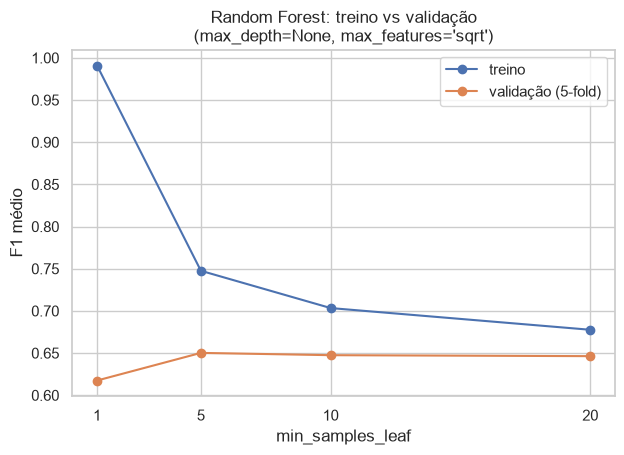

In [9]:
curve = grid_results[
    grid_results["max_depth"].isna() & (grid_results["max_features"] == "sqrt")
].sort_values("min_samples_leaf")

plt.figure(figsize=(7, 4.5))
plt.plot(curve["min_samples_leaf"], curve["train_f1_mean"], marker="o", label="treino")
plt.plot(curve["min_samples_leaf"], curve["cv_f1_mean"], marker="o", label="validação (5-fold)")
plt.xticks(curve["min_samples_leaf"].astype(int))
plt.xlabel("min_samples_leaf")
plt.ylabel("F1 médio")
plt.title("Random Forest: treino vs validação\n(max_depth=None, max_features='sqrt')")
plt.legend()
plt.show()

**Leitura:** a busca confirma a configuração que já estava em
`churn.models` — `min_samples_leaf=5`, sem limite de profundidade,
`max_features="sqrt"` — como a melhor das 24 combinações (F1 médio em CV
de 0,650). O modelo campeão salvo, portanto, não muda.

O gráfico mostra o porquê. Com folhas de 1 cliente, as árvores decoram o
treino (F1 de treino ≈ 0,99) e generalizam pior (≈ 0,62 na validação):
é overfitting. Exigir pelo menos 5 clientes por folha regulariza o modelo
e fecha boa parte dessa distância; acima disso ele começa a perder sinal.

As 10 melhores configurações ficam a menos de 0,005 de F1 entre si — bem
abaixo do desvio-padrão entre folds (≈ 0,018). O desempenho do Random
Forest é estável em relação aos hiperparâmetros, então uma busca maior
dificilmente traria ganho relevante. O registro completo dos 24
experimentos fica em [`docs/rf_grid_search.csv`](../docs/rf_grid_search.csv).

## 5. Campeão em detalhe: matriz de confusão, ROC e Precisão-Recall

Re-treinamos os três pipelines no treino completo e avaliamos no teste
(mesmo procedimento de `train.py`) para poder plotar as curvas — os
números batem com a tabela da seção 1.

In [10]:
fitted = {}
for name, pipeline in get_candidates().items():
    pipeline.fit(X_train, y_train)
    fitted[name] = pipeline

champion = fitted[champion_name]
baseline = fitted[BASELINE_NAME]


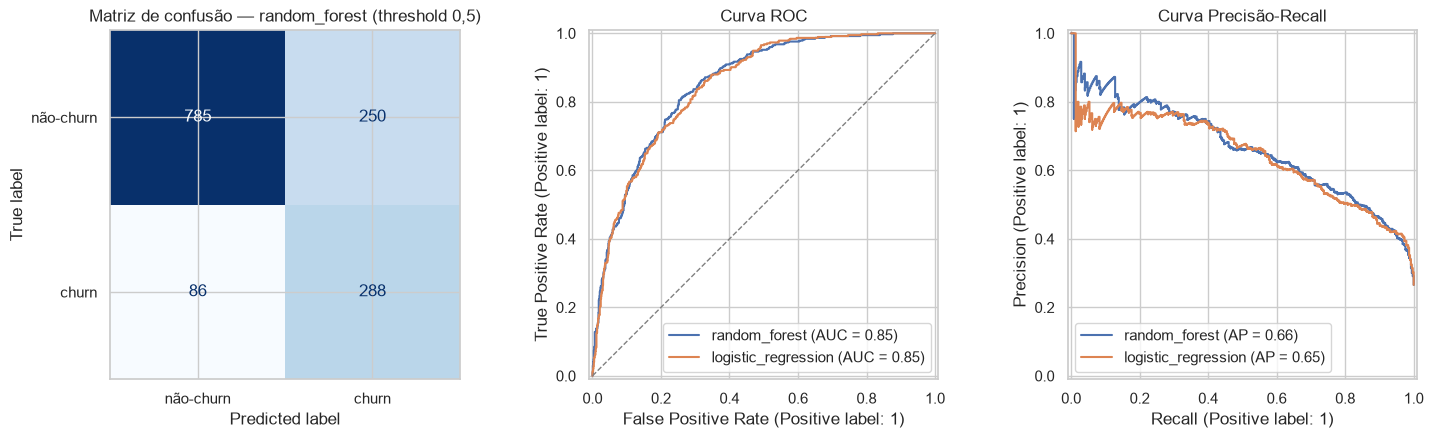

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

ConfusionMatrixDisplay.from_estimator(
    champion, X_test, y_test, display_labels=["não-churn", "churn"],
    cmap="Blues", ax=axes[0], colorbar=False,
)
axes[0].set_title(f"Matriz de confusão — {champion_name} (threshold 0,5)")

RocCurveDisplay.from_estimator(champion, X_test, y_test, name=champion_name, ax=axes[1])
RocCurveDisplay.from_estimator(baseline, X_test, y_test, name=BASELINE_NAME, ax=axes[1])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
axes[1].set_title("Curva ROC")

PrecisionRecallDisplay.from_estimator(champion, X_test, y_test, name=champion_name, ax=axes[2])
PrecisionRecallDisplay.from_estimator(baseline, X_test, y_test, name=BASELINE_NAME, ax=axes[2])
axes[2].set_title("Curva Precisão-Recall")

plt.tight_layout()
plt.show()


## 6. Métrica de negócio: Precisão@K em função de K

A decisão de retenção (ML Canvas, bloco 3) é por ranking, não pelo corte
de 0,5 — por isso olhamos como a precisão do topo da fila se comporta
conforme o time de retenção consegue abordar uma fatia maior ou menor da
base, para os três modelos.

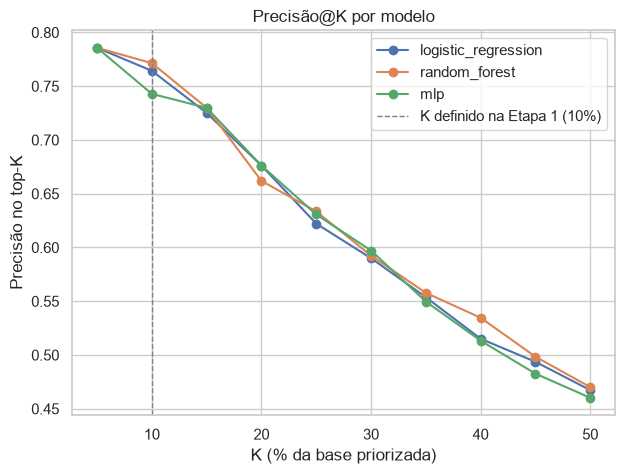

In [12]:
def precision_at_k_curve(y_true, y_proba, k_percents):
    y_true = np.asarray(y_true)
    y_proba = np.asarray(y_proba)
    order = np.argsort(y_proba)[::-1]
    return [
        y_true[order[: max(1, int(len(y_true) * k))]].mean()
        for k in k_percents
    ]

k_percents = np.arange(0.05, 0.55, 0.05)

plt.figure(figsize=(7, 5))
for name, pipeline in fitted.items():
    proba = pipeline.predict_proba(X_test)[:, 1]
    curve = precision_at_k_curve(y_test, proba, k_percents)
    plt.plot(k_percents * 100, curve, marker="o", label=name)

plt.axvline(config.TOP_K_PERCENT * 100, linestyle="--", color="gray", linewidth=1,
            label=f"K definido na Etapa 1 ({config.TOP_K_PERCENT:.0%})")
plt.xlabel("K (% da base priorizada)")
plt.ylabel("Precisão no top-K")
plt.title("Precisão@K por modelo")
plt.legend()
plt.show()


**Leitura:** o Random Forest mantém a maior (ou empatada) precisão em
praticamente toda a faixa de K plausível para um time de retenção — não é
uma vantagem que só aparece no K=10% usado como suposição inicial. Isso
reforça que a escolha do campeão é robusta a mudanças no orçamento real de
retenção, não um artefato do K escolhido.


## 7. O que o campeão aprendeu: importância das features

Na EDA (Etapa 1) levantamos a hipótese de que `contract`,
`internet_service` e `payment_method` dominariam a importância nos modelos
de árvore. Para checar, usamos *permutation importance* no conjunto de
teste: embaralhamos uma feature por vez e medimos quanto o AUC-PR do
campeão cai. Três escolhas importam aqui:

- A permutação é feita nas **features originais**, antes do one-hot,
  porque o Pipeline recebe os dados brutos. Assim `contract` aparece como
  uma variável só, e não espalhada em três colunas binárias.
- A métrica é o **AUC-PR**, que não depende do corte de 0,5 e acompanha o
  uso real do modelo como ranking.
- Não usamos a importância por impureza (`feature_importances_` do Random
  Forest), que tende a inflar features numéricas contínuas, com muitos
  pontos de corte possíveis.

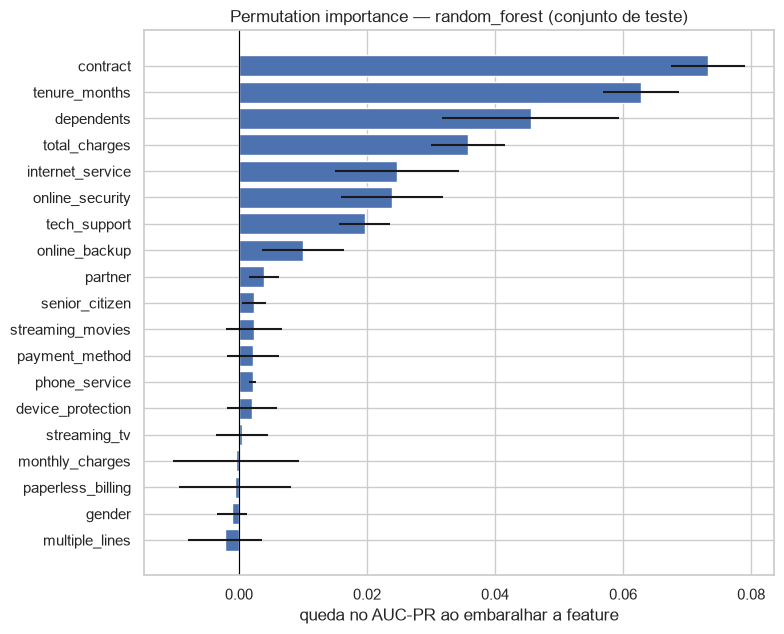

,importancia,desvio
contract,0.0733,0.0058
tenure_months,0.0628,0.0060
dependents,0.0456,0.0139
total_charges,0.0357,0.0058
internet_service,0.0247,0.0097
online_security,0.0239,0.0080
tech_support,0.0196,0.0039
online_backup,0.0100,0.0064
partner,0.0039,0.0024
senior_citizen,0.0024,0.0019


In [13]:
perm = permutation_importance(
    champion,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=config.RANDOM_STATE,
    n_jobs=-1,
)

importances = (
    pd.DataFrame(
        {"importancia": perm.importances_mean, "desvio": perm.importances_std},
        index=X_test.columns,
    )
    .sort_values("importancia", ascending=False)
)

plt.figure(figsize=(8, 6.5))
plt.barh(
    importances.index[::-1],
    importances["importancia"][::-1],
    xerr=importances["desvio"][::-1],
    color="#4C72B0",
)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("queda no AUC-PR ao embaralhar a feature")
plt.title(f"Permutation importance — {champion_name} (conjunto de teste)")
plt.tight_layout()
plt.show()

importances.round(4)

Duas divergências em relação à EDA pedem explicação: `payment_method` com
importância perto de zero e `dependents` entre as primeiras. Cruzamos as
variáveis para entender:

In [14]:
print("Contrato por forma de pagamento (proporcao de cada linha):")
display(pd.crosstab(df_clean["payment_method"], df_clean["contract"], normalize="index").round(3))

month_to_month = df_clean[df_clean["contract"] == "Month-to-month"]
display(pd.DataFrame({
    "churn_base_toda": df_clean.groupby("dependents")["churn_value"].mean(),
    "churn_so_contrato_mensal": month_to_month.groupby("dependents")["churn_value"].mean(),
}).round(3))

print("Mensalidade media por tipo de internet:")
display(df_clean.groupby("internet_service")["monthly_charges"].mean().round(2))

Contrato por forma de pagamento (proporcao de cada linha):


contract,Month-to-month,One year,Two year
payment_method,,,
Bank transfer (automatic),0.381,0.253,0.365
Credit card (automatic),0.357,0.261,0.382
Electronic check,0.782,0.147,0.071
Mailed check,0.554,0.209,0.237


,churn_base_toda,churn_so_contrato_mensal
dependents,,
No,0.326,0.478
Yes,0.065,0.167


Mensalidade media por tipo de internet:


internet_service
DSL            58.10
Fiber optic    91.50
No             21.08
Name: monthly_charges, dtype: float64

**Leitura:**

- **Confirmado:** `contract` é a feature mais importante, seguida de
  `tenure_months` — os dois sinais mais fortes da EDA. `internet_service`
  também contribui, em posição intermediária.
- **Não confirmado:** `payment_method` fica perto de zero, apesar da taxa
  de churn de 45% em *Electronic check*. A tabela explica: 78% de quem
  paga por *Electronic check* está em contrato mensal. Quando embaralhamos
  só a forma de pagamento, o modelo continua vendo o contrato e reconhece
  o mesmo risco. A permutação mede a contribuição *única* de cada feature,
  e o sinal de `payment_method` já está quase todo em `contract`. O mesmo
  vale para `monthly_charges`, que o modelo recupera de `internet_service`
  (a fibra é o plano mais caro) e de `total_charges`.
- **Surpresa:** `dependents` aparece em 3º lugar. Clientes com dependentes
  cancelam 6,5%, contra 32,6% de quem não tem — e a diferença se mantém
  dentro do contrato mensal (16,7% contra 47,8%), então não é efeito do
  contrato. É um sinal que a EDA da Etapa 1 não explorou.
- **`gender` não pesa** (importância dentro do ruído): o modelo não usa
  gênero para ranquear risco. Isso não basta para afirmar ausência de viés
  — a análise de desempenho por subgrupo fica para a Etapa 4 —, mas é um
  ponto a registrar no Model Card.

## 8. Justificativa da escolha do campeão

**Campeão: Random Forest.**

1. **Critério primário (F1 na validação cruzada, Etapa 1):** maior F1
   médio em 5-fold CV (0,650 contra 0,640 da Regressão Logística). O
   resultado se confirma no teste (0,632 contra 0,617), que não participou
   da escolha.
2. **Robustez:** distribuição de F1 por fold comparável em variância à da
   Regressão Logística (seção 3) — a vantagem não é fruto de instabilidade.
3. **Hiperparâmetros validados:** a busca em grade (seção 4) manteve a
   configuração original como a melhor de 24 combinações. Como nada mudou,
   a tabela da seção 1 continua comparando modelos com o mesmo nível de
   ajuste — o campeão não foi favorecido por ter sido o único otimizado.
4. **Métrica de negócio (Precision@K):** mantém a maior precisão no topo
   do ranking em toda a faixa razoável de K (seção 6), não só no K=10%
   assumido inicialmente — é o critério que mais importa para a decisão
   real de retenção (ML Canvas, blocos 1 e 3).
5. **Explicável para o negócio:** as features que mais pesam no ranking
   (seção 7) — tipo de contrato e tempo de casa — são sinais de risco que
   o time de retenção reconhece, o que facilita justificar quem entra na
   lista.
6. **MLP descartado apesar da maior precisão isolada:** seu recall baixo
   (0,473) decorre, em parte, de uma limitação conhecida — o
   `MLPClassifier` do Scikit-Learn não aceita `class_weight`, então ele é
   o único candidato sem correção para o desbalanceamento de classes
   (73,5%/26,5%). Isso é registrado como limitação do modelo, não como um
   ponto a favor dele.

## 9. Limitações conhecidas (para o Model Card)

- Só o Random Forest passou por busca de hiperparâmetros (seção 4);
  Regressão Logística e MLP usam valores fixos e razoáveis, não
  otimizados. Um MLP ajustado poderia reduzir a distância para o campeão.
- `MLPClassifier` não suporta `class_weight`; é o único candidato sem
  balanceamento de classes explícito.
- Precisão/recall/F1 reportados usam o corte padrão de 0,5, mas a decisão
  de negócio real é por ranking (top-K) — os dois são coerentes aqui
  (seção 6), mas isso pode não se sustentar se a distribuição de scores
  mudar com novos dados.
- A validação cruzada roda só no conjunto de treino (escolha do campeão e
  busca de hiperparâmetros); as métricas finais reportadas vêm de um único
  split de teste (20%).
- A importância por permutação mede a contribuição *única* de cada
  feature: variáveis correlacionadas (como `payment_method` e `contract`)
  dividem o crédito e podem parecer menos importantes do que são
  isoladamente (seção 7).